# 06 · Modelo final, test, interpretación y despliegue

**Jorge Javier Palma Martínez · ML1 FIUNA · 2026**

Protocolo: `deduplicated-v2-2026-11-22`.

La decisión final se congela en selection_decision.json usando todos los candidatos de validación. Se reentrena la configuración elegida de cada familia con train+validation, y después se calculan las métricas del test reservado. El modelo final serializa selección, escalado y clasificador juntos, evitando diferencias entre notebook y API.

Las curvas de aprendizaje usan 3 folds estratificados dentro de train: son diagnósticas posteriores a la búsqueda y no validación anidada independiente. La importancia mostrada pertenece al XGBoost comparado y no explica causalmente al SVM final. Se informa kappa cuadrático como métrica ordinal adicional.

Los límites incluyen falta de IDs de paciente, posibles recortes relacionados, formato asociado al grado, promedio bilateral y ausencia de validación externa/clínica. Las métricas viejas no se comparan directamente con las actuales. La API y el dashboard son una demostración académica.

In [1]:
from pathlib import Path
import sys,json
import pandas as pd
from IPython.display import display,Image
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'src/workflow.py').exists())
if str(ROOT) not in sys.path:sys.path.insert(0,str(ROOT))
from src import workflow
# False: show the executed experiment exports; True: recompute this stage.
RECOMPUTE=False


## Ejecutar o consultar la etapa

Los resultados mostrados se cargan de los artefactos calculados por `python scripts/run_pipeline.py`. Para reconstruir, ejecutar los seis notebooks en orden con `RECOMPUTE=True`; para leer la entrega, dejarlo en `False`. Las implementaciones completas están en `src/workflow.py`.

In [2]:
if RECOMPUTE:
    workflow.evaluate()
display(pd.read_csv(ROOT/'reports/comparacion_modelos.csv'))
display(json.loads((ROOT/'reports/modelos_avanzados_metrics.json').read_text(encoding='utf-8'))['classification_report'])

,Modelo,family,validation_f1,Accuracy (%),Balanced Acc (%),F1 Macro,F1 Weighted,Precision Macro,Recall Macro
0,SVM ANOVA160 C=10,SVM,0.588111,72.9958,71.8515,0.720672,0.725753,0.730798,0.718515
1,XGBoost 300 rondas,XGBoost,0.556524,71.7300,68.3437,0.684732,0.707190,0.700792,0.683437
2,Random Forest n=300 hoja=2,Random Forest,0.543773,67.0886,63.1185,0.643583,0.662737,0.684158,0.631185
3,Logística C=0.1,Logística,0.562956,65.4008,64.0147,0.626743,0.656784,0.621404,0.640147
4,SVD k=10,SVD,0.493101,59.0717,56.5862,0.564520,0.587438,0.566100,0.565862
5,Dummy mayoritaria,Dummy,0.092508,30.8017,20.0000,0.094194,0.145066,0.061603,0.200000


{'Normal': {'precision': 0.7380952380952381,
  'recall': 0.8493150684931506,
  'f1-score': 0.7898089171974523,
  'support': 73.0},
 'Dudosa': {'precision': 0.71875,
  'recall': 0.6571428571428571,
  'f1-score': 0.6865671641791045,
  'support': 70.0},
 'Leve': {'precision': 0.6071428571428571,
  'recall': 0.5151515151515151,
  'f1-score': 0.5573770491803278,
  'support': 33.0},
 'Moderada': {'precision': 0.84,
  'recall': 0.7,
  'f1-score': 0.7636363636363637,
  'support': 30.0},
 'Severa': {'precision': 0.75,
  'recall': 0.8709677419354839,
  'f1-score': 0.8059701492537313,
  'support': 31.0},
 'accuracy': 0.729957805907173,
 'macro avg': {'precision': 0.7307976190476191,
  'recall': 0.7185154365446014,
  'f1-score': 0.7206719286893959,
  'support': 237.0},
 'weighted avg': {'precision': 0.7286040787623065,
  'recall': 0.729957805907173,
  'f1-score': 0.7257525764002478,
  'support': 237.0}}

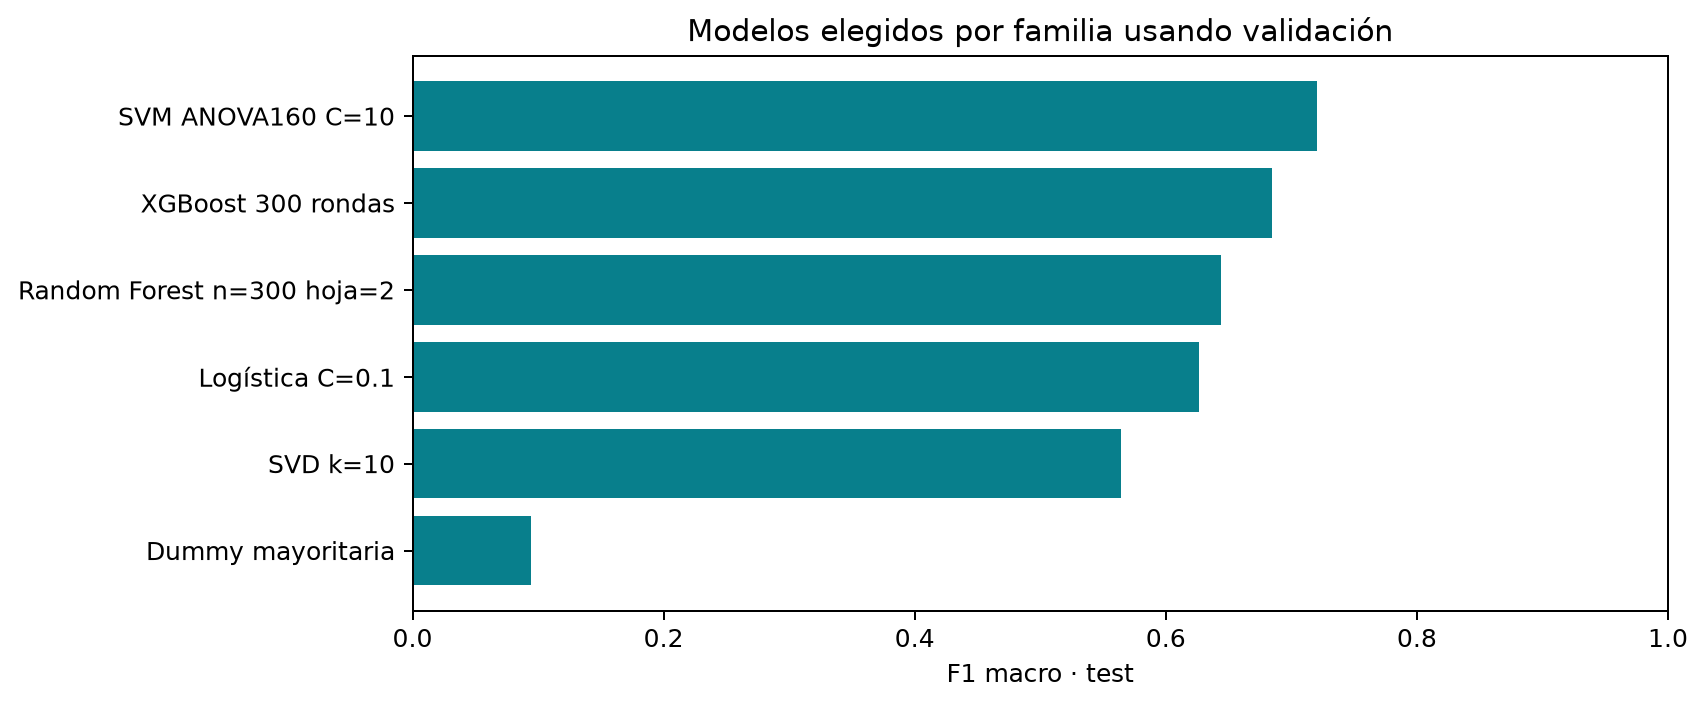

In [3]:
display(Image(filename=str(ROOT/'reports/figures/comparacion_modelos.png')))

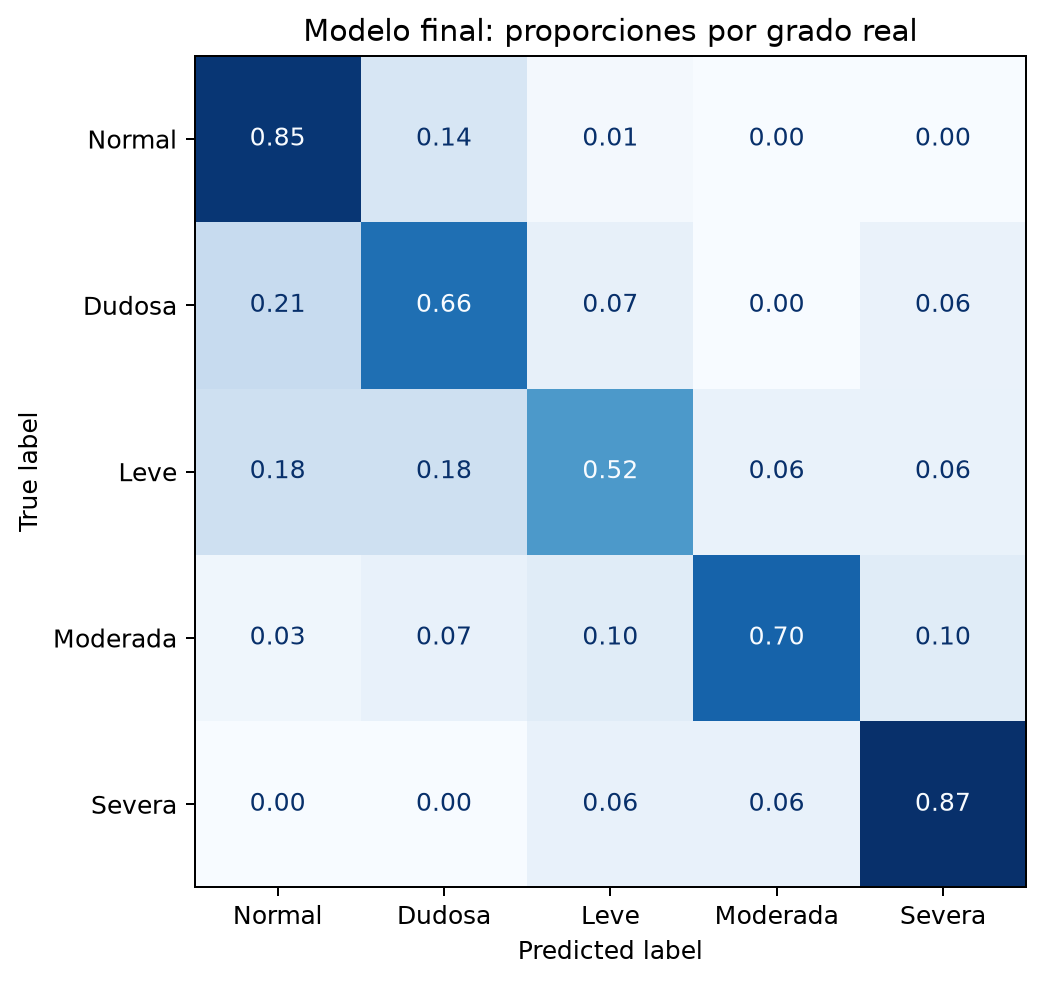

In [4]:
display(Image(filename=str(ROOT/'reports/figures/final_confusion_normalizada.png')))

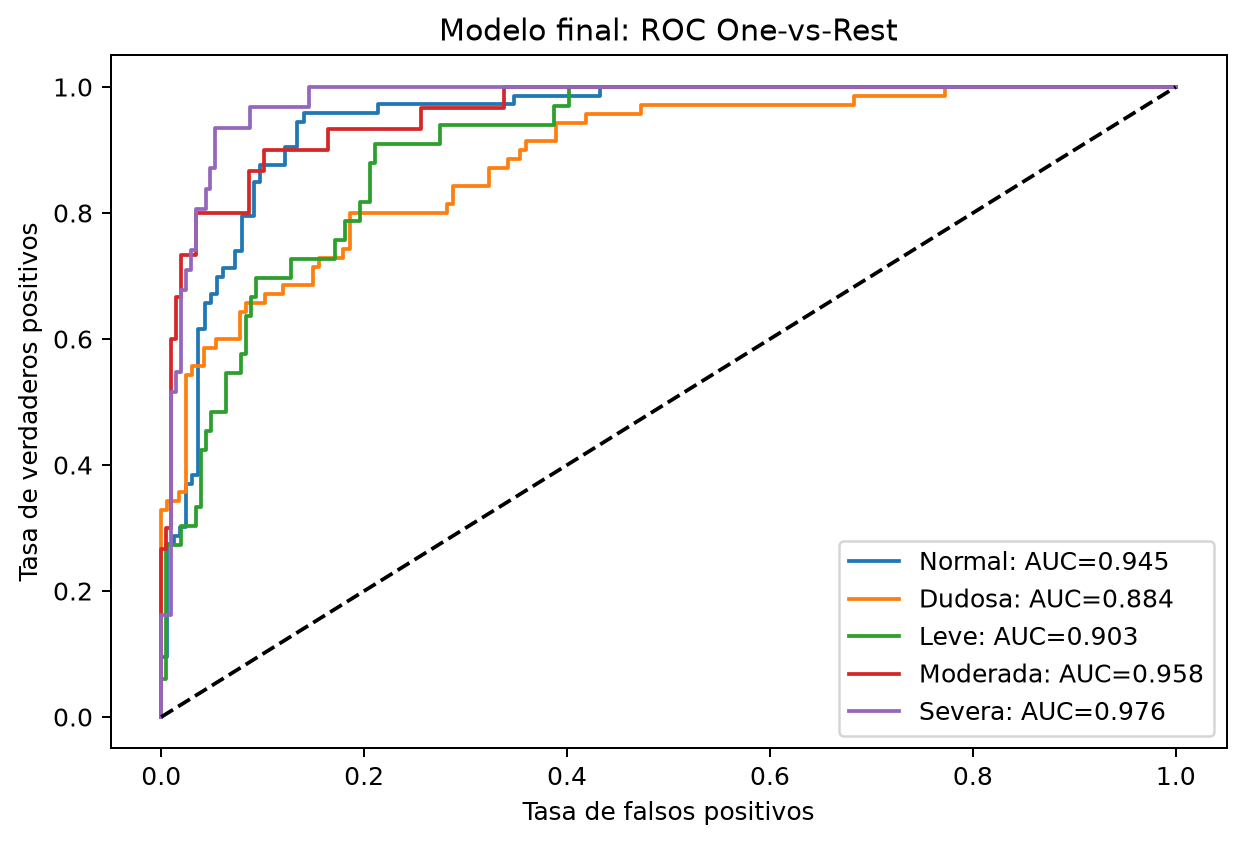

In [5]:
display(Image(filename=str(ROOT/'reports/figures/modelos_avanzados_roc_curves.png')))

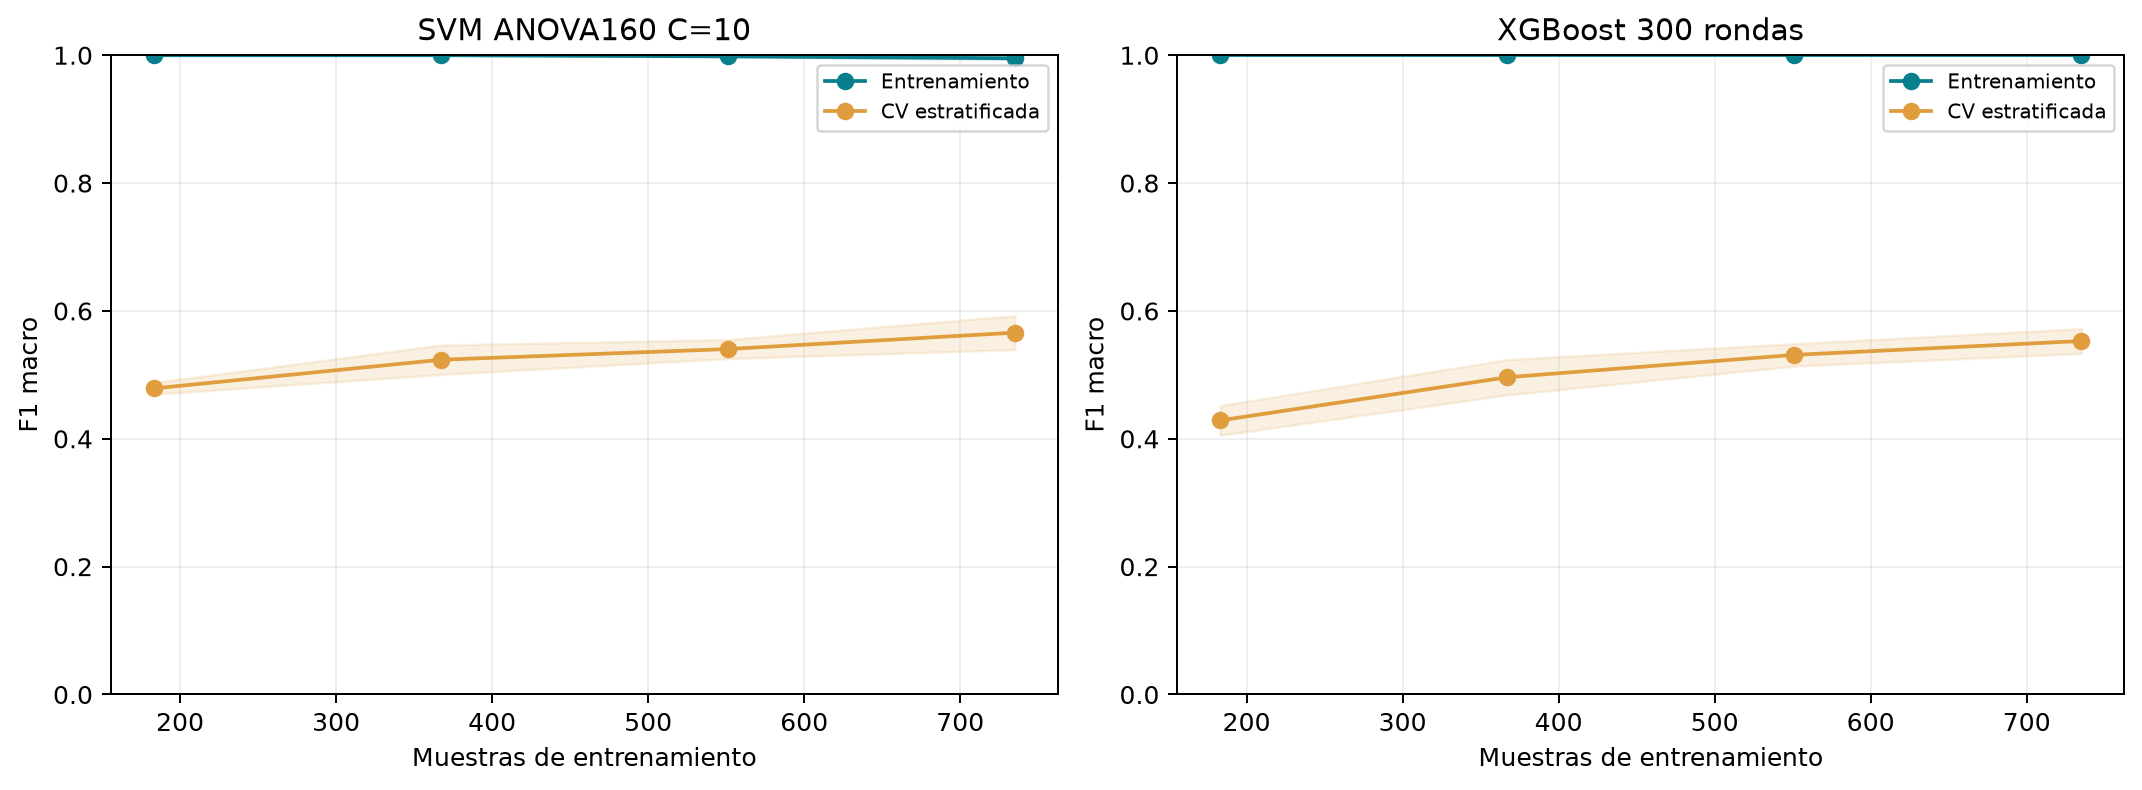

In [6]:
display(Image(filename=str(ROOT/'reports/figures/modelos_avanzados_learning_curves.png')))

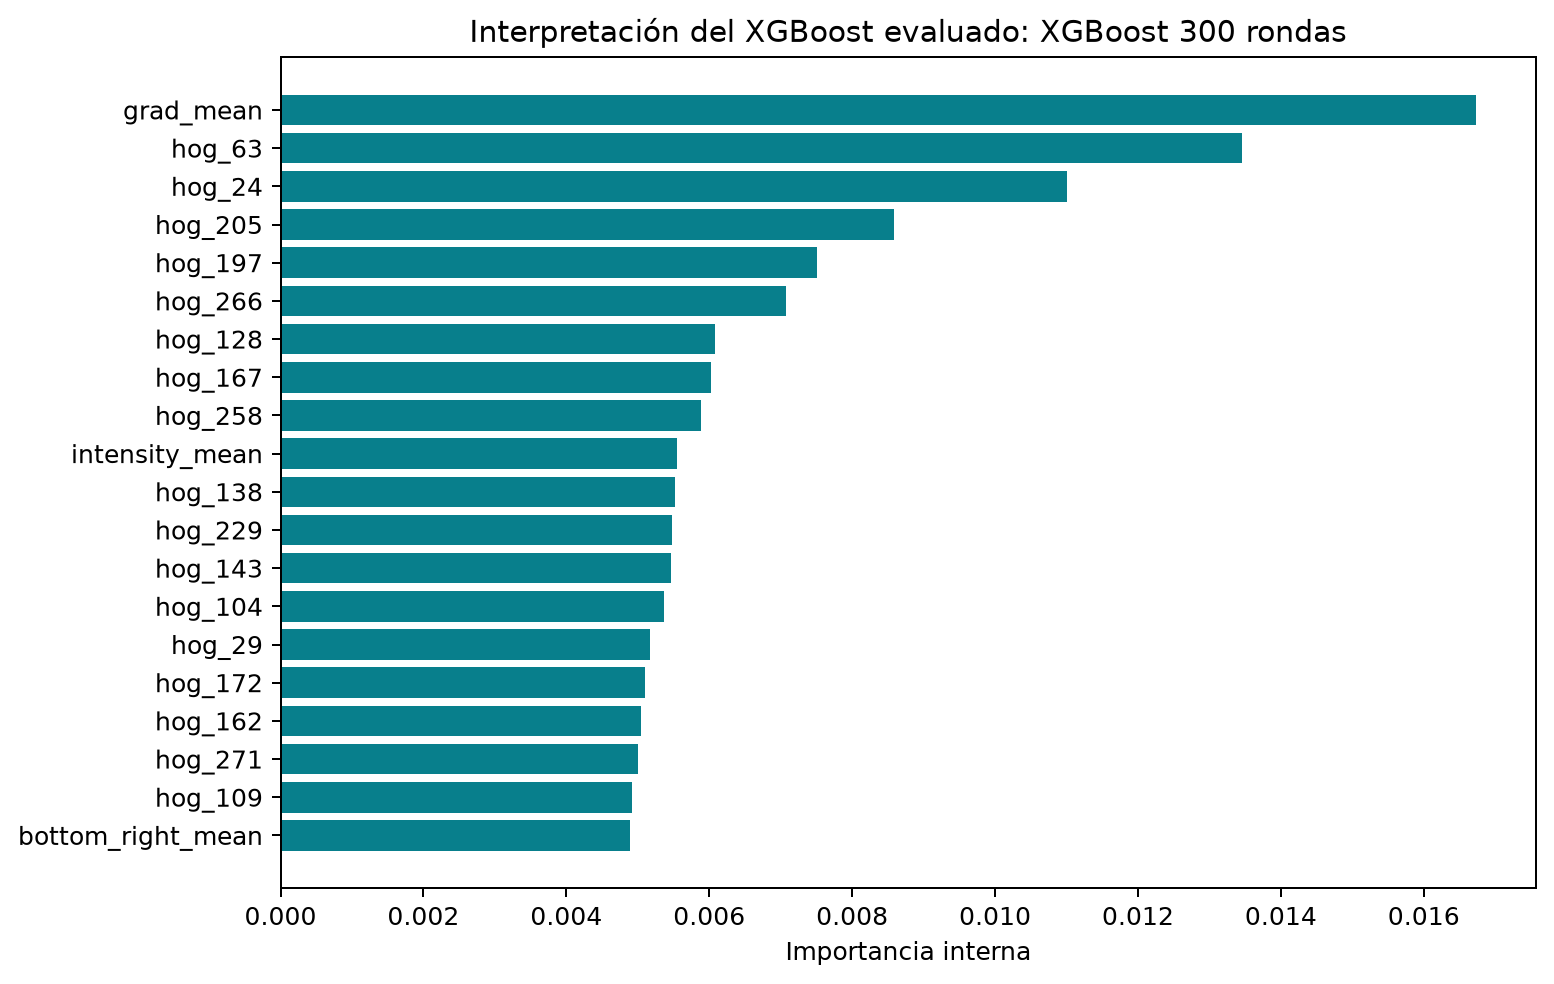

In [7]:
display(Image(filename=str(ROOT/'reports/figures/modelos_avanzados_feature_importance.png')))